# Verificación de la capa Gold — Iceberg

Comprobamos las dos tablas gold tras los ETL:
- `nessie.nyc.yellow_taxi_trips` (trip-level enriquecido)
- `nessie.nyc.pickup_demand_zone_hour` (agregado por zona × hora)

Para cada una validamos referencias Nessie, esquema, snapshots, particionado,
calidad de datos y consistencia con la capa silver. La auditoría va más allá
del audit gate del ETL: verifica conservación de filas (silver→gold), ausencia
de zonas NULL tras el join, coherencia de las columnas derivadas y, en el
agregado, conservación del total de pickups.

In [1]:
import re

from common.spark_factory import get_spark
from common import nessie_manager as nessie
from pyspark.sql.functions import (
    avg, col, count, max as spark_max, min as spark_min,
    month as spark_month, rand, stddev, sum as spark_sum, when,
    year as spark_year,
)
import pandas as pd
import matplotlib.pyplot as plt

spark = get_spark("verify-gold-iceberg")
nessie.set_spark_branch(spark, "main")
spark.version

26/07/14 16:45:00 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


'3.5.8'

## 1. Catálogo Nessie — Referencias y namespaces

In [2]:
# Todas las referencias relevantes para gold (main + tags + ramas WAP residuales si las hay).
nessie.print_references(spark)

  * Branch bronze                                   bf8e6494579d
  * Branch main                                     c577394a0346
  * Branch silver                                   8bbc7435661a
    Tag    bronze-taxi_zone_lookup-2026             bf8e6494579d
    Tag    bronze-yellow_taxi-2023                  6d69f7093dc9
    Tag    bronze-yellow_taxi-2024                  1c1fdaf5d2e3
    Tag    bronze-yellow_taxi-2025                  3191b472cb24
    Tag    gold-pickup_demand_zone_hour-2023        8b8ef9c9e815
    Tag    gold-pickup_demand_zone_hour-2024        fbe8ff3bb080
    Tag    gold-pickup_demand_zone_hour-2025        c577394a0346
    Tag    gold-yellow_taxi_trips-2023              ac0fe2b5b662
    Tag    gold-yellow_taxi_trips-2024              3d78ec52a3d4
    Tag    gold-yellow_taxi_trips-2025              197cc46e37ad
    Tag    silver-taxi_zone_lookup-2026             8bbc7435661a
    Tag    silver-yellow_taxi-2023                  c8ec624d8bad
    Tag    silver-yellow_

> **Nota — alcance de 9 meses.** Gold cubre el Q1 completo (enero–marzo) de
> 2023, 2024 y 2025: 9 meses en total. En esta ejecución ningún mes superó el
> umbral `MAX_DROP_RATIO = 0.3` del audit gate de silver, así que no hay tags
> `review/` en cuarentena y los 9 meses se propagan íntegros de bronze a silver
> y de silver a gold. Si en una ejecución futura algún mes fallara el audit,
> aparecería como tag `review/silver-yellow_taxi-{YYYY}-{MM}` y no llegaría a
> gold — el comportamiento esperado «audit falla → cuarentena + continuar».

In [3]:
# Namespaces y tablas en main
spark.sql("SHOW NAMESPACES IN nessie").show()
spark.sql("SHOW TABLES IN nessie.nyc").show(truncate=False)

+---------+
|namespace|
+---------+
|      nyc|
+---------+

+---------+-----------------------+-----------+
|namespace|tableName              |isTemporary|
+---------+-----------------------+-----------+
|nyc      |pickup_demand_zone_hour|false      |
|nyc      |yellow_taxi_trips      |false      |
+---------+-----------------------+-----------+



## 2. yellow_taxi_trips — Propiedades y esquema

In [4]:
spark.sql("DESCRIBE TABLE EXTENDED nessie.nyc.yellow_taxi_trips").show(200, truncate=False)

+-----------------------------+--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+-------+
|col_name                     |data_type                                                                                                                                                                                                                                                                                                     |comment|
+-----------------------------+-------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

In [5]:
# Esquema con tipos
spark.table("nessie.nyc.yellow_taxi_trips").printSchema()

root
 |-- pickup_datetime: timestamp_ntz (nullable = false)
 |-- dropoff_datetime: timestamp_ntz (nullable = false)
 |-- pickup_year: integer (nullable = false)
 |-- pickup_month: integer (nullable = false)
 |-- pickup_week: integer (nullable = false)
 |-- pickup_dow: integer (nullable = false)
 |-- pickup_hour: integer (nullable = false)
 |-- trip_duration_minutes: double (nullable = false)
 |-- pu_location_id: integer (nullable = false)
 |-- pu_borough: string (nullable = false)
 |-- pu_zone: string (nullable = false)
 |-- pu_service_zone: string (nullable = true)
 |-- do_location_id: integer (nullable = false)
 |-- do_borough: string (nullable = false)
 |-- do_zone: string (nullable = false)
 |-- do_service_zone: string (nullable = true)
 |-- vendor_id: integer (nullable = false)
 |-- ratecode_id: integer (nullable = false)
 |-- payment_type: long (nullable = false)
 |-- store_and_fwd_flag: string (nullable = false)
 |-- passenger_count: double (nullable = false)
 |-- trip_distance:

## 3. yellow_taxi_trips — Snapshots e historial

In [6]:
spark.sql("""
    SELECT committed_at, snapshot_id, parent_id, operation,
           summary['added-records'] AS added_records,
           summary['total-records'] AS total_records
    FROM nessie.nyc.yellow_taxi_trips.snapshots
    ORDER BY committed_at
""").show(truncate=False)

+-----------------------+-------------------+-------------------+---------+-------------+-------------+
|committed_at           |snapshot_id        |parent_id          |operation|added_records|total_records|
+-----------------------+-------------------+-------------------+---------+-------------+-------------+
|2026-07-14 10:00:11.474|3534792227236239733|NULL               |append   |2728997      |2728997      |
|2026-07-14 10:00:39.038|1875068919812773310|3534792227236239733|append   |2585494      |5314491      |
|2026-07-14 10:01:07.222|7567115528941955943|1875068919812773310|append   |3009227      |8323718      |
|2026-07-14 10:01:32.648|159536616832701792 |7567115528941955943|append   |2565646      |10889364     |
|2026-07-14 10:01:59.333|5070678718835607303|159536616832701792 |append   |2564824      |13454188     |
|2026-07-14 10:02:27.395|4720840344013054209|5070678718835607303|append   |2859065      |16313253     |
|2026-07-14 10:02:54.215|3670929783555001266|4720840344013054209

## 3b. Crecimiento por tag anual — ambas tablas gold

Un tag por año (`gold-{tabla}-{YYYY}`) marca el snapshot publicado tras el
último mes mergeado de ese año, para cada una de las dos tablas gold
(`yellow_taxi_trips` y `pickup_demand_zone_hour`). Contamos filas a la altura
de cada tag.

In [7]:
TABLES = [
    ("yellow_taxi_trips", "nessie.nyc.yellow_taxi_trips"),
    ("pickup_demand_zone_hour", "nessie.nyc.pickup_demand_zone_hour"),
]

refs = nessie.list_references(spark)
tag_pattern = re.compile(r"gold-(?P<table>[a-z_]+)-(?P<year>\d{4})")
yearly_tags = {tbl: [] for tbl, _ in TABLES}
for r in refs:
    # Nessie devuelve refType en mixed-case ("Tag" / "Branch"), no en mayusculas.
    # Comparar contra "TAG" en exacto descartaba todos los tags y dejaba rows=[].
    if (r["refType"] or "").upper() != "TAG":
        continue
    m = tag_pattern.fullmatch(r["name"])
    if m and m.group("table") in yearly_tags:
        yearly_tags[m.group("table")].append(r["name"])
for tbl in yearly_tags:
    yearly_tags[tbl].sort()

rows = []
for tbl, fqn in TABLES:
    for tag in yearly_tags[tbl]:
        nessie.set_spark_branch(spark, tag)
        n = spark.table(fqn).count()
        rows.append((tbl, tag, n))
nessie.set_spark_branch(spark, "main")

if not rows:
    print("No hay tags anuales de gold. Ejecuta antes los pipelines de gold.")
else:
    growth_df = spark.createDataFrame(rows, ["tabla", "tag", "filas"])
    growth_df.orderBy("tabla", "tag").show(truncate=False)

+-----------------------+---------------------------------+--------+
|tabla                  |tag                              |filas   |
+-----------------------+---------------------------------+--------+
|pickup_demand_zone_hour|gold-pickup_demand_zone_hour-2023|198084  |
|pickup_demand_zone_hour|gold-pickup_demand_zone_hour-2024|411262  |
|pickup_demand_zone_hour|gold-pickup_demand_zone_hour-2025|631388  |
|yellow_taxi_trips      |gold-yellow_taxi_trips-2023      |8323718 |
|yellow_taxi_trips      |gold-yellow_taxi_trips-2024      |16313253|
|yellow_taxi_trips      |gold-yellow_taxi_trips-2025      |24393325|
+-----------------------+---------------------------------+--------+



## 4. yellow_taxi_trips — Particionado y ficheros

In [8]:
# Particiones (particionado oculto por month(pickup_datetime))
spark.sql("""
    SELECT partition, record_count, file_count
    FROM nessie.nyc.yellow_taxi_trips.partitions
    ORDER BY partition
""").show(50, truncate=False)

+---------+------------+----------+
|partition|record_count|file_count|
+---------+------------+----------+
|{636}    |2728997     |1         |
|{637}    |2585494     |1         |
|{638}    |3009227     |1         |
|{648}    |2565646     |1         |
|{649}    |2564824     |1         |
|{650}    |2859065     |1         |
|{660}    |2658715     |1         |
|{661}    |2515296     |1         |
|{662}    |2906061     |1         |
+---------+------------+----------+



In [9]:
# Ficheros físicos — conteo, filas y tamaño total en una sola pasada.
stats = spark.sql(
    "SELECT * FROM nessie.nyc.yellow_taxi_trips.files"
).agg(
    count("*").alias("file_count"),
    spark_sum("file_size_in_bytes").alias("total_bytes"),
    spark_sum("record_count").alias("total_rows"),
).first()
print(f"Ficheros: {stats['file_count']}")
print(f"Filas   : {stats['total_rows']:,}")
print(f"Tamaño  : {stats['total_bytes']/(1024**2):,.1f} MiB")

26/07/14 16:45:24 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.


Ficheros: 9
Filas   : 24,393,325
Tamaño  : 458.4 MiB


## 5. yellow_taxi_trips — Auditoría de calidad

Los gates del ETL ya filtran lo más grueso, pero re-verificamos sobre la tabla
publicada. Lo que comprobamos:

- **Zonas no nulas**: silver garantiza PU/DO en `[1, 265]` y la tabla de zonas
  los cubre todos → tras el `LEFT JOIN`, ninguna columna `pu_borough` /
  `do_borough` debe ser NULL.
- **Duración positiva**: silver enforza `pickup < dropoff` →
  `trip_duration_minutes > 0` siempre.
- **Coherencia de las columnas derivadas**: `pickup_year` debe coincidir con
  `year(pickup_datetime)`, idem mes.

In [10]:
# Auditoría en una sola pasada (igual patrón que el ETL y el silver verify).
trips = spark.table("nessie.nyc.yellow_taxi_trips")

checks = {
    "pu_borough nulo":          col("pu_borough").isNull(),
    "do_borough nulo":          col("do_borough").isNull(),
    "duración no positiva":     col("trip_duration_minutes") <= 0,
    "pickup_year incoherente":  spark_year("pickup_datetime") != col("pickup_year"),
    "pickup_month incoherente": spark_month("pickup_datetime") != col("pickup_month"),
}

audit = trips.agg(
    count("*").alias("filas_totales"),
    *[spark_sum(when(cond, 1).otherwise(0)).alias(label)
      for label, cond in checks.items()],
).first().asDict()

total_rows = audit.pop("filas_totales")
print(f"Filas totales: {total_rows:,}\n")

width = max(len(k) for k in audit)
for label, n in audit.items():
    flag = "OK" if n == 0 else "FALLO"
    print(f"  [{flag}] {label.ljust(width)} : {n}")

assert all(n == 0 for n in audit.values()), "La auditoría de calidad ha fallado"
print("\nTodas las comprobaciones de calidad OK")

Filas totales: 24,393,325

  [OK] pu_borough nulo          : 0
  [OK] do_borough nulo          : 0
  [OK] duración no positiva     : 0
  [OK] pickup_year incoherente  : 0
  [OK] pickup_month incoherente : 0

Todas las comprobaciones de calidad OK


## 6. yellow_taxi_trips — Silver vs Gold (conservación de filas)

El ETL de gold hace un `LEFT JOIN` 1:1 con la tabla de zonas. Las filas de gold
deben coincidir exactamente con las de silver mes a mes. Si hay desviación,
señala un fallo en el join o filas perdidas en la transformación.

In [11]:
# Conteo silver por (año, mes) — se reutiliza en la sección 10.
nessie.set_spark_branch(spark, "silver")
silver_per_month = (
    spark.table("nessie.nyc.yellow_taxi")
    .groupBy(
        spark_year("tpep_pickup_datetime").alias("año"),
        spark_month("tpep_pickup_datetime").alias("mes"),
    )
    .agg(count("*").alias("filas_silver"))
    .orderBy("año", "mes")
    .toPandas()
)
nessie.set_spark_branch(spark, "main")

gold_counts = (
    spark.table("nessie.nyc.yellow_taxi_trips")
    .groupBy(col("pickup_year").alias("año"), col("pickup_month").alias("mes"))
    .agg(count("*").alias("filas_gold"))
    .orderBy("año", "mes")
    .toPandas()
)

cmp = silver_per_month.merge(gold_counts, on=["año", "mes"], how="outer").fillna(0)
cmp["dif"] = cmp["filas_gold"] - cmp["filas_silver"]
print(cmp.to_string(index=False))

 año  mes  filas_silver  filas_gold  dif
2023    1       2728997     2728997    0
2023    2       2585494     2585494    0
2023    3       3009227     3009227    0
2024    1       2565646     2565646    0
2024    2       2564824     2564824    0
2024    3       2859065     2859065    0
2025    1       2658715     2658715    0
2025    2       2515296     2515296    0
2025    3       2906061     2906061    0


In [12]:
mismatched = cmp[cmp["dif"] != 0]
if mismatched.empty:
    print("Silver vs Gold: mismo número de filas en todos los meses.")
else:
    print("DISCREPANCIA detectada — investígala antes de consumir gold:")
    print(mismatched.to_string(index=False))

Silver vs Gold: mismo número de filas en todos los meses.


## 7. yellow_taxi_trips — Muestra de datos

In [13]:
# Muestra representativa: orderBy(rand(seed)) baraja la tabla entera para que
# las filas salgan de meses y zonas distintos. Un show(5) sin barajar devuelve
# siempre las primeras filas de la primera particion escaneada (un unico mes).
spark.table("nessie.nyc.yellow_taxi_trips").orderBy(rand(42)).show(5, truncate=False)

+-------------------+-------------------+-----------+------------+-----------+----------+-----------+---------------------+--------------+----------+----------------------------+---------------+--------------+----------+---------------------+---------------+---------+-----------+------------+------------------+---------------+-------------+-----------+----------+------------+-------+-----+---------------------+--------------------+-----------+------------------+------------+
|pickup_datetime    |dropoff_datetime   |pickup_year|pickup_month|pickup_week|pickup_dow|pickup_hour|trip_duration_minutes|pu_location_id|pu_borough|pu_zone                     |pu_service_zone|do_location_id|do_borough|do_zone              |do_service_zone|vendor_id|ratecode_id|payment_type|store_and_fwd_flag|passenger_count|trip_distance|fare_amount|tip_amount|tolls_amount|mta_tax|extra|improvement_surcharge|congestion_surcharge|airport_fee|cbd_congestion_fee|total_amount|
+-------------------+-------------------

## 8. pickup_demand_zone_hour — Propiedades y esquema

In [14]:
spark.sql("DESCRIBE TABLE EXTENDED nessie.nyc.pickup_demand_zone_hour").show(200, truncate=False)

+-----------------------------+--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+-------+
|col_name                     |data_type                                                                                                                                                                                                                                                                                                     |comment|
+-----------------------------+-------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

In [15]:
spark.table("nessie.nyc.pickup_demand_zone_hour").printSchema()

root
 |-- hour_bucket: timestamp_ntz (nullable = false)
 |-- pu_location_id: integer (nullable = false)
 |-- pu_borough: string (nullable = false)
 |-- pu_zone: string (nullable = false)
 |-- pu_service_zone: string (nullable = true)
 |-- hour_year: integer (nullable = false)
 |-- hour_month: integer (nullable = false)
 |-- hour_week: integer (nullable = false)
 |-- hour_dow: integer (nullable = false)
 |-- hour_of_day: integer (nullable = false)
 |-- n_pickups: long (nullable = false)
 |-- total_revenue: double (nullable = false)
 |-- avg_fare: double (nullable = false)
 |-- avg_tip: double (nullable = false)
 |-- avg_distance: double (nullable = false)
 |-- avg_passengers: double (nullable = false)



## 9. pickup_demand_zone_hour — Snapshots y particionado

In [16]:
spark.sql("""
    SELECT committed_at, snapshot_id, operation,
           summary['added-records'] AS added_records,
           summary['total-records'] AS total_records
    FROM nessie.nyc.pickup_demand_zone_hour.snapshots
    ORDER BY committed_at
""").show(truncate=False)

+-----------------------+-------------------+---------+-------------+-------------+
|committed_at           |snapshot_id        |operation|added_records|total_records|
+-----------------------+-------------------+---------+-------------+-------------+
|2026-07-14 10:04:22.404|8127645003794282824|append   |67276        |67276        |
|2026-07-14 10:04:29.909|8137425581159640786|append   |60742        |128018       |
|2026-07-14 10:04:35.306|2842791533074344113|append   |70066        |198084       |
|2026-07-14 10:04:40.076|2421282509404807730|append   |69955        |268039       |
|2026-07-14 10:04:44.556|5635135073034531505|append   |67393        |335432       |
|2026-07-14 10:04:49.032|6992005337933430918|append   |75830        |411262       |
|2026-07-14 10:04:53.418|1786278413790658488|append   |73955        |485217       |
|2026-07-14 10:04:57.841|8058998040375580617|append   |68136        |553353       |
|2026-07-14 10:05:02.241|8130865656184881586|append   |78035        |631388 

In [17]:
spark.sql("""
    SELECT partition, record_count, file_count
    FROM nessie.nyc.pickup_demand_zone_hour.partitions
    ORDER BY partition
""").show(50, truncate=False)

+---------+------------+----------+
|partition|record_count|file_count|
+---------+------------+----------+
|{636}    |67276       |1         |
|{637}    |60742       |1         |
|{638}    |70066       |1         |
|{648}    |69955       |1         |
|{649}    |67393       |1         |
|{650}    |75830       |1         |
|{660}    |73955       |1         |
|{661}    |68136       |1         |
|{662}    |78035       |1         |
+---------+------------+----------+



## 10. pickup_demand_zone_hour — Auditoría: conservación de pickups

`sum(n_pickups)` mes a mes debe igualar el conteo de silver para ese mes —
todas las filas de silver tienen que estar contabilizadas en algún grupo
`(pu_location_id, hour_bucket)`. Si no, hay agregación con pérdida o filtro
indebido.

In [18]:
# silver_per_month ya calculado en la sección 6 — lo reutilizamos aquí.
demand_per_month = (
    spark.table("nessie.nyc.pickup_demand_zone_hour")
    .groupBy(col("hour_year").alias("año"), col("hour_month").alias("mes"))
    .agg(spark_sum("n_pickups").alias("pickups_gold"))
    .orderBy("año", "mes")
    .toPandas()
)

conserv = silver_per_month.merge(demand_per_month, on=["año", "mes"], how="outer").fillna(0)
conserv["dif"] = conserv["pickups_gold"] - conserv["filas_silver"]
print(conserv.to_string(index=False))

 año  mes  filas_silver  pickups_gold  dif
2023    1       2728997       2728997    0
2023    2       2585494       2585494    0
2023    3       3009227       3009227    0
2024    1       2565646       2565646    0
2024    2       2564824       2564824    0
2024    3       2859065       2859065    0
2025    1       2658715       2658715    0
2025    2       2515296       2515296    0
2025    3       2906061       2906061    0


In [19]:
mismatched = conserv[conserv["dif"] != 0]
if mismatched.empty:
    print("Silver vs Gold: el total de pickups se conserva en todos los meses.")
else:
    print("INCOHERENCIA DE CONSERVACIÓN — los pickups no se conservan en la agregación:")
    print(mismatched.to_string(index=False))

Silver vs Gold: el total de pickups se conserva en todos los meses.


## 11. pickup_demand_zone_hour — Calidad y distribución

In [20]:
# Auditoría + distribución de n_pickups en una sola pasada.
demand = spark.table("nessie.nyc.pickup_demand_zone_hour")

stats = demand.agg(
    count("*").alias("total_groups"),
    spark_sum(when(col("pu_borough").isNull(), 1).otherwise(0)).alias("null_zone"),
    spark_min("n_pickups").alias("min_pickups"),
    spark_max("n_pickups").alias("max_pickups"),
    avg("n_pickups").alias("avg_pickups"),
    stddev("n_pickups").alias("stddev_pickups"),
).first()

print(f"Grupos (zona, hora) totales: {stats['total_groups']:,}")
print(f"pu_borough NULL: {stats['null_zone']}")
assert stats["null_zone"] == 0, "El join con la tabla de zonas ha introducido NULL en la tabla de demanda"

print("\nDistribución de n_pickups:")
print(f"  mín         : {stats['min_pickups']}")
print(f"  máx         : {stats['max_pickups']}")
print(f"  media       : {stats['avg_pickups']:.2f}")
print(f"  desv. típica: {stats['stddev_pickups']:.2f}")

Grupos (zona, hora) totales: 631,388
pu_borough NULL: 0

Distribución de n_pickups:
  mín         : 1
  máx         : 750
  media       : 38.63
  desv. típica: 68.13


In [21]:
# Top 10 zonas por pickups totales
top_zones = (
    demand.groupBy("pu_location_id", "pu_borough", "pu_zone")
    .agg(spark_sum("n_pickups").alias("pickups_totales"))
    .orderBy(col("pickups_totales").desc())
    .limit(10)
)
top_zones.show(truncate=False)

+--------------+----------+----------------------------+---------------+
|pu_location_id|pu_borough|pu_zone                     |pickups_totales|
+--------------+----------+----------------------------+---------------+
|237           |Manhattan |Upper East Side South       |1251649        |
|161           |Manhattan |Midtown Center              |1235801        |
|236           |Manhattan |Upper East Side North       |1144196        |
|162           |Manhattan |Midtown East                |928092         |
|186           |Manhattan |Penn Station/Madison Sq West|926052         |
|230           |Manhattan |Times Sq/Theatre District   |875495         |
|132           |Queens    |JFK Airport                 |860764         |
|142           |Manhattan |Lincoln Square East         |847895         |
|163           |Manhattan |Midtown North               |749604         |
|170           |Manhattan |Murray Hill                 |738984         |
+--------------+----------+------------------------

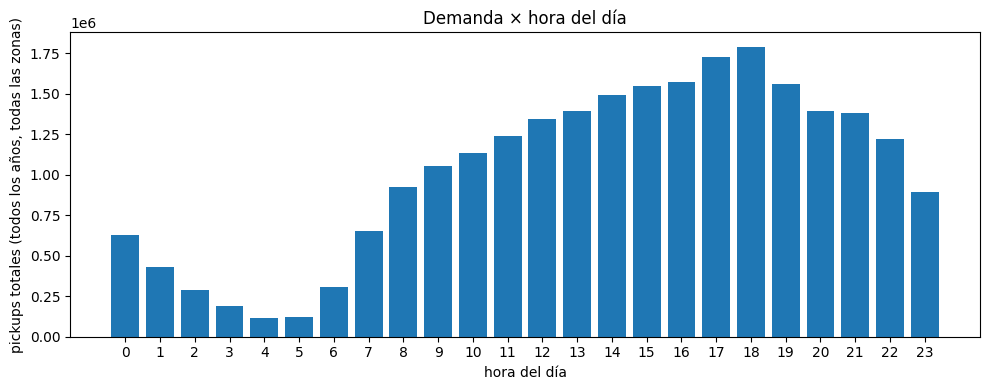

In [22]:
# Patrón demanda × hora del día: ¿el pico está donde esperamos?
hourly = (
    demand.groupBy("hour_of_day")
    .agg(spark_sum("n_pickups").alias("pickups_totales"))
    .orderBy("hour_of_day")
    .toPandas()
)
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(hourly["hour_of_day"], hourly["pickups_totales"])
ax.set_xlabel("hora del día")
ax.set_ylabel("pickups totales (todos los años, todas las zonas)")
ax.set_title("Demanda × hora del día")
ax.set_xticks(range(0, 24))
plt.tight_layout()

## 12. Conclusiones

La capa gold publicada en `main` pasa todas las verificaciones definidas en este notebook sobre los 9 meses ingeridos (Q1 de 2023, 2024 y 2025):

- **Alcance de los datos (sección 1)**. Gold cubre los 9 meses del Q1 de 2023, 2024 y 2025. En esta ejecución ningún mes superó el umbral `MAX_DROP_RATIO = 0.3` del audit gate de silver, por lo que no hay tags `review/` en cuarentena y los 9 meses se propagan íntegros hasta gold.
- **Conservación de filas silver → gold (sección 6)**. `yellow_taxi_trips` tiene exactamente las mismas filas que `silver.yellow_taxi` en cada uno de los 9 meses (`dif = 0` en toda la tabla, 24.393.325 filas en total). El `LEFT JOIN` con la tabla de zonas no introduce duplicados ni pérdidas — los IDs PU/DO de silver están todos cubiertos por `silver.taxi_zone_lookup`.
- **Conservación de pickups en el agregado (sección 10)**. `sum(n_pickups)` de `pickup_demand_zone_hour` iguala al conteo de silver en los 9 meses (`dif = 0`). El group-by por `(pu_location_id, hour_bucket)` no descarta filas: 631.388 grupos contabilizan los 24.393.325 viajes.
- **Zonas NULL (secciones 5 y 11)**. Cero filas con `pu_borough` o `do_borough` NULL en `yellow_taxi_trips`, y cero `pu_borough` NULL en `pickup_demand_zone_hour`. El audit gate del ETL ya lo garantizaba; la tabla publicada lo confirma.
- **Coherencia de las columnas derivadas (sección 5)**. `pickup_year` y `pickup_month` coinciden con `year/month(pickup_datetime)` en todas las filas, y `trip_duration_minutes > 0` siempre. Esto último no es trivial: gold calcula la duración como `(unix_timestamp(dropoff) - unix_timestamp(pickup)) / 60`, que trunca a segundos; el hecho de que ninguna fila salga con duración 0 indica que en estos 9 meses no hay viajes sub-segundo que silver haya dejado pasar.
- **Particionado razonable (secciones 4 y 9)**. Iceberg ha creado 9 particiones mensuales en cada tabla — una por mes ingerido, sin fragmentación interna (1 fichero por partición). En `yellow_taxi_trips` los ficheros pesan ~51 MiB de media (458 MiB / 9), tamaño cómodo para escaneo por mes. El particionado `months(...)` y la naturaleza single-writer de los ETL explican esta distribución limpia.
- **Patrón horario plausible (sección 11)**. El histograma «Demanda × hora del día» reproduce la forma esperada de NYC: valle nocturno (~04:00–05:00) y pico de tarde (~18:00–19:00). El top-10 de zonas con más pickups está dominado por Manhattan (Upper East Side South / North, Midtown Center / East, Times Square, Penn Station) más JFK Airport — coherente con los puntos de mayor densidad de demanda en el dataset.

La capa gold queda lista para consumo por las pipelines de ML (`src/ml/`), que leen exclusivamente de `nessie.nyc.*` en `main`.